In [1]:
# ==========================================
# 1. SETUP E BIBLIOTECAS
# ==========================================

!pip install skops huggingface_hub -q

import math
import numpy as np
import pandas as pd
import os
import warnings
import matplotlib.pyplot as plt
from sklearn.calibration import CalibratedClassifierCV, CalibrationDisplay
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GroupKFold, GroupShuffleSplit
from sklearn.pipeline import Pipeline
import skops.io as sio
import sys, json, sklearn, skops
from sklearn.metrics import accuracy_score, precision_score
from IPython.display import display
from huggingface_hub import HfApi, login
from kaggle_secrets import UserSecretsClient

warnings.filterwarnings('ignore', category=DeprecationWarning)
warnings.filterwarnings('ignore', category=ResourceWarning)

In [2]:
# ==========================================
# 2. MOTOR DE CONFIANÇA E ABSTENÇÃO (NÚCLEO)
# ==========================================
Z = 1.96 # Constante para IC de 95%

def wilson(k, n):
    """Calcula o intervalo de confiança de Wilson para penalizar precisão em amostras pequenas."""
    if n == 0: return 0.0, 1.0
    p, d = k / n, 1 + Z * Z / n
    c = (p + Z * Z / (2 * n)) / d
    h = Z * math.sqrt(p * (1 - p) / n + Z * Z / (4 * n * n)) / d
    return max(0.0, c - h), min(1.0, c + h)

def ece(p, y, bins=10):
    """Calcula o Expected Calibration Error (ECE) - o quanto as probabilidades refletem a realidade."""
    idx = np.minimum((p * bins).astype(int), bins - 1)
    return float(sum(abs(p[idx == b].mean() - y[idx == b].mean()) * (idx == b).mean() for b in range(bins) if (idx == b).any()))

def escolher_limiar(conf, acertou, alvo=0.95, min_n=50):
    """Encontra o menor limiar onde o limite inferior de Wilson atinge a meta (95%)."""
    for t in np.linspace(0.5, 0.999, 200):
        sel = conf >= t
        n, k = int(sel.sum()), int(acertou[sel].sum())
        if n >= min_n and wilson(k, n)[0] >= alvo: return float(t)
    return None

def decidir(p_neg, t_neg, t_pos):
    """Aplica a abstenção: 1 (Negativa Segura), 0 (Positiva Segura) ou -1 (Revisão Humana)."""
    d = np.full(len(p_neg), -1)
    if t_neg is not None: d[p_neg >= t_neg] = 1
    if t_pos is not None: d[(1 - p_neg) >= t_pos] = 0
    return d

def treinar_e_avaliar(tv, teste, vetorizador, alvo=0.95, seed=42):
    """Pipeline completo: separação por cliente, treino, calibração fora-da-dobra e teste cego."""
    gss = GroupShuffleSplit(n_splits=1, test_size=0.3, random_state=seed)
    i_tr, i_val = next(gss.split(tv, groups=tv["cliente"]))
    tr, val = tv.iloc[i_tr], tv.iloc[i_val]
    
    base = Pipeline([
        ("tfidf", vetorizador),
        ("clf", LogisticRegression(max_iter=1000, random_state=seed))
    ])
    
    # Calibração Out-of-Fold para evitar vazamento
    folds = list(GroupKFold(n_splits=5).split(tr["texto"], tr["y"], groups=tr["cliente"]))
    cal = CalibratedClassifierCV(base, method="isotonic", cv=folds) 
    cal.fit(tr["texto"], tr["y"])
    
    pv, yv = cal.predict_proba(val["texto"])[:, 1], val["y"].to_numpy()
    t_neg = escolher_limiar(pv, yv == 1, alvo)
    t_pos = escolher_limiar(1 - pv, yv == 0, alvo)
    
    pt, yt = cal.predict_proba(teste["texto"])[:, 1], teste["y"].to_numpy()
    d = decidir(pt, t_neg, t_pos)
    
    auto = d != -1
    k, n = int((d[auto] == yt[auto]).sum()), int(auto.sum())
    lo, hi = wilson(k, n)
    auto_neg = d == 1
    k_neg, n_neg = int((d[auto_neg] == yt[auto_neg]).sum()), int(auto_neg.sum())
    
    return dict(t_neg=t_neg, t_pos=t_pos, n_total=len(yt), n_auto=n, 
                cob_global=n / len(yt) if len(yt) else 0, prec_global=k / n if n else float("nan"), ic95=(lo, hi),
                cob_neg=n_neg / len(yt) if len(yt) else 0, prec_neg=k_neg / n_neg if n_neg else float("nan"),
                ece_teste=ece(pt, yt), pt=pt, yt=yt, modelo_treinado=cal)

In [3]:
# ==========================================
# 3. PREPARO TEMPORAL E ISOLAMENTO DE CLIENTES
# ==========================================
reviews = pd.read_csv('/kaggle/input/datasets/olistbr/brazilian-ecommerce/olist_order_reviews_dataset.csv')
orders = pd.read_csv('/kaggle/input/datasets/olistbr/brazilian-ecommerce/olist_orders_dataset.csv')
customers = pd.read_csv('/kaggle/input/datasets/olistbr/brazilian-ecommerce/olist_customers_dataset.csv')

df = reviews.merge(orders[['order_id', 'customer_id', 'order_purchase_timestamp']], on='order_id', how='left')
df = df.merge(customers[['customer_id', 'customer_unique_id']], on='customer_id', how='left')
df = df.dropna(subset=['review_comment_message', 'order_purchase_timestamp']).drop_duplicates(subset=['review_comment_message'])
df = df[df['review_score'] != 3].copy()
df['is_negative'] = df['review_score'].apply(lambda x: 1 if x <= 2 else 0)
df['order_purchase_timestamp'] = pd.to_datetime(df['order_purchase_timestamp'])
df = df.sort_values(by='order_purchase_timestamp').reset_index(drop=True)

split_idx = int(len(df) * 0.8)
train_val_df, test_df = df.iloc[:split_idx].copy(), df.iloc[split_idx:].copy()

# Zero Leakage: Removemos do teste qualquer cliente que já foi visto no passado
test_df = test_df[~test_df['customer_unique_id'].isin(train_val_df['customer_unique_id'])]

tv = train_val_df.rename(columns={"review_comment_message": "texto", "is_negative": "y", "customer_unique_id": "cliente"})[["texto", "y", "cliente"]]
teste = test_df.rename(columns={"review_comment_message": "texto", "is_negative": "y", "customer_unique_id": "cliente"})[["texto", "y", "cliente"]]

print(f"Base de Treino/Validação (Passado): {len(tv)} avaliações")
print(f"Base de Teste Inédito (Futuro): {len(teste)} avaliações")

Base de Treino/Validação (Passado): 26320 avaliações
Base de Teste Inédito (Futuro): 6482 avaliações


In [4]:
# ==========================================
# 4. TREINAMENTO COMPARATIVO (MODELOS A e B)
# ==========================================
print("Treinando Modelo A (TF-IDF Palavras)...")
vet_palavras = TfidfVectorizer(strip_accents="unicode", ngram_range=(1, 2), min_df=2, sublinear_tf=True)
res_a = treinar_e_avaliar(tv, teste, vet_palavras)

print("Treinando Modelo B (TF-IDF Caracteres n: 2-5)...")
vet_char = TfidfVectorizer(analyzer="char_wb", strip_accents="unicode", ngram_range=(2, 5), min_df=2, sublinear_tf=True)
res_b = treinar_e_avaliar(tv, teste, vet_char)

print("Treinamentos concluídos com sucesso!")

Treinando Modelo A (TF-IDF Palavras)...
Treinando Modelo B (TF-IDF Caracteres n: 2-5)...
Treinamentos concluídos com sucesso!


COMPARATIVO DE MODELOS


Métrica no Teste Cego,Modelo A (Palavras),Modelo B (Caracteres)
Cobertura Global (Volume Automatizado),74.21%,74.48%
Precisão Global (Confiança),96.96%,96.42%
Cobertura da Classe Negativa,3.47%,3.27%
Precisão da Classe Negativa (Minority),98.67%,98.11%
Erro Esperado de Calibração (ECE),0.0142,0.0146



Conclusão: O Modelo A (Palavras) é o escolhido para produção devido à sua superioridade na precisão da classe minoritária (reclamações) e melhor calibração (menor ECE).


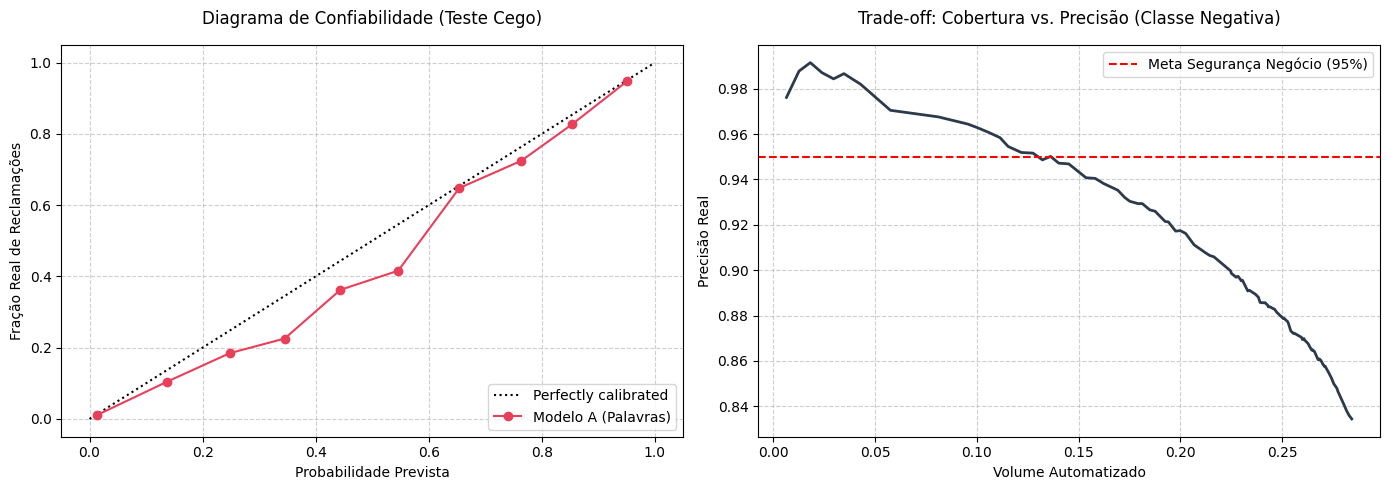

In [5]:
# ==========================================
# 5. RESULTADOS, ESCOLHA DO CAMPEÃO E DIAGNÓSTICO VISUAL
# ==========================================

# 1. Tabela Comparativa
df_comp = pd.DataFrame({
    "Métrica no Teste Cego": [
        "Cobertura Global (Volume Automatizado)", 
        "Precisão Global (Confiança)", 
        "Cobertura da Classe Negativa", 
        "Precisão da Classe Negativa (Minority)", 
        "Erro Esperado de Calibração (ECE)"
    ],
    "Modelo A (Palavras)": [
        f"{res_a['cob_global']*100:.2f}%", 
        f"{res_a['prec_global']*100:.2f}%", 
        f"{res_a['cob_neg']*100:.2f}%", 
        f"{res_a['prec_neg']*100:.2f}%", 
        f"{res_a['ece_teste']:.4f}"
    ],
    "Modelo B (Caracteres)": [
        f"{res_b['cob_global']*100:.2f}%", 
        f"{res_b['prec_global']*100:.2f}%", 
        f"{res_b['cob_neg']*100:.2f}%", 
        f"{res_b['prec_neg']*100:.2f}%", 
        f"{res_b['ece_teste']:.4f}"
    ]
})

print("COMPARATIVO DE MODELOS")
display(df_comp.style.hide(axis="index").set_properties(**{'text-align': 'center'}))

print("\nConclusão: O Modelo A (Palavras) é o escolhido para produção devido à sua superioridade na precisão da classe minoritária (reclamações) e melhor calibração (menor ECE).")

# 2. Gráficos do Modelo Campeão
pt, yt = res_a['pt'], res_a['yt']
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

CalibrationDisplay.from_predictions(yt, pt, n_bins=10, ax=ax1, name="Modelo A (Palavras)", color="#E83F5B", marker="o")
ax1.set_title("Diagrama de Confiabilidade (Teste Cego)", pad=15)
ax1.set_xlabel("Probabilidade Prevista")
ax1.set_ylabel("Fração Real de Reclamações")
ax1.grid(True, linestyle="--", alpha=0.6)

limiares, coberturas, precisoes = np.linspace(0.5, 0.99, 100), [], []
for t in limiares:
    auto_neg = pt >= t
    if auto_neg.sum() > 0:
        precisoes.append((yt[auto_neg] == 1).sum() / auto_neg.sum())
        coberturas.append(auto_neg.sum() / len(yt))

ax2.plot(coberturas, precisoes, color="#2D3A4B", lw=2)
ax2.axhline(y=0.95, color='r', linestyle='--', label="Meta Segurança Negócio (95%)")
ax2.set_title("Trade-off: Cobertura vs. Precisão (Classe Negativa)", pad=15)
ax2.set_xlabel("Volume Automatizado")
ax2.set_ylabel("Precisão Real")
ax2.legend()
ax2.grid(True, linestyle="--", alpha=0.6)
plt.tight_layout()
plt.show()

# Garante que a pasta 'docs' existe antes de tentar salvar a imagem dentro dela
os.makedirs("docs", exist_ok=True)

fig.savefig("docs/diagnostico_modelo.png", dpi=300, bbox_inches="tight")

In [6]:
# ==========================================
# 6. AUDITORIA, BASELINES E TESTES DE SANIDADE
# ==========================================

# 1. VERSÕES REAIS DO AMBIENTE (para o requirements.txt e Model Card)
print("=== AMBIENTE ===")
print(f"Python: {sys.version.split()[0]}")
for pkg in [np, pd, sklearn, skops]:
    print(f"{pkg.__name__}=={pkg.__version__}")

# 2. BASELINES REAIS NO TESTE CEGO
yt = res_a["yt"]
pt = res_a["pt"]
prop_pos = float((yt == 0).mean())
n_neg_total = int((yt == 1).sum())

# Baseline 2: Mesmo modelo sem calibração e sem abstenção (corte 0.5)
base_sem_cal = Pipeline([
    ("tfidf", TfidfVectorizer(strip_accents="unicode", ngram_range=(1, 2), min_df=2, sublinear_tf=True)),
    ("clf", LogisticRegression(max_iter=1000, random_state=42))
])
base_sem_cal.fit(tv["texto"], tv["y"])
pred_base = base_sem_cal.predict(teste["texto"])
acc_base = accuracy_score(yt, pred_base)

print("\n=== BASELINES E COMPOSIÇÃO DO TESTE ===")
print(f"Total teste: {len(yt)} | Positivas: {(yt==0).sum()} ({prop_pos*100:.1f}%) | Negativas: {n_neg_total} ({(1-prop_pos)*100:.1f}%)")
print(f"Baseline 1 (Sempre 'positiva'): {prop_pos*100:.2f}% de acurácia")
print(f"Baseline 2 (Sem calibração/abstenção, corte 0.5): {acc_base*100:.2f}% de acurácia em 100% de cobertura")
print(f"Negativas automatizadas pelo Modelo A: {int((pt >= res_a['t_neg']).sum())} de {n_neg_total} ({(pt >= res_a['t_neg']).sum()/n_neg_total*100:.1f}% das reclamações)")

# 3. EXEMPLOS REAIS DO TESTE (Para a Análise de Erros do README)
d_a = decidir(pt, res_a["t_neg"], res_a["t_pos"])
df_analise = teste.copy()
df_analise["p_neg"] = pt
df_analise["decisao"] = d_a

print("\n=== 5 ERROS REAIS NA AUTOMAÇÃO ===")
erros_auto = df_analise[(df_analise["decisao"] != -1) & (df_analise["decisao"] != df_analise["y"])]
for _, row in erros_auto.head(5).iterrows():
    print(f"[Real={row['y']} | Prev={row['decisao']} | p_neg={row['p_neg']:.3f}] {row['texto'][:120]}")

print("\n=== 5 CASOS REAIS ENVIADOS À REVISÃO (Abstenção) ===")
revisao = df_analise[df_analise["decisao"] == -1]
for _, row in revisao.sample(5, random_state=42).iterrows():
    print(f"[Real={row['y']} | p_neg={row['p_neg']:.3f}] {row['texto'][:120]}")

# 4. TESTES DE SANIDADE (Unit Tests)
assert len(set(tv["cliente"]).intersection(set(teste["cliente"]))) == 0, "Vazamento de cliente!"
assert wilson(95, 100)[0] < 0.95 and wilson(100, 100)[0] >= 0.95, "Cálculo de Wilson incorreto!"
assert res_a["prec_global"] >= 0.95, "Precisão no teste ficou abaixo da meta!"
print("\n✅ Todos os 3 testes de sanidade passaram!")

=== AMBIENTE ===
Python: 3.13.18
numpy==2.1.3
pandas==2.3.3
sklearn==1.6.1
skops==0.16.0

=== BASELINES E COMPOSIÇÃO DO TESTE ===
Total teste: 6482 | Positivas: 4777 (73.7%) | Negativas: 1705 (26.3%)
Baseline 1 (Sempre 'positiva'): 73.70% de acurácia
Baseline 2 (Sem calibração/abstenção, corte 0.5): 93.43% de acurácia em 100% de cobertura
Negativas automatizadas pelo Modelo A: 225 de 1705 (13.2% das reclamações)

=== 5 ERROS REAIS NA AUTOMAÇÃO ===
[Real=1 | Prev=0 | p_neg=0.061] O produto é bom, mas tem um cheiro insuportável de cola de sapateiro 
[Real=1 | Prev=0 | p_neg=0.169] ruin
[Real=1 | Prev=0 | p_neg=0.024] O produto chegou e estragou sozinho
[Real=1 | Prev=0 | p_neg=0.005] Dentro do prazo previsto.
[Real=1 | Prev=0 | p_neg=0.008] material com uma qualidade muito boa,letra para leitura muito boa,e foi entregue tudo certo.

=== 5 CASOS REAIS ENVIADOS À REVISÃO (Abstenção) ===
[Real=1 | p_neg=0.914] Comprei duas cadeiras, uma o assento ñ encaixa corretamente e a outra veio sem as

In [7]:
# ==========================================
# 7. EXPORTAÇÃO E DEPLOY NO HUGGING FACE
# ==========================================

# Salva o modelo físico
sio.dump(res_a['modelo_treinado'], "modelo_olist_tfidf_calibrado.skops")

try:
    hf_token = UserSecretsClient().get_secret("HF_TOKEN")
    login(token=hf_token)
    
    api = HfApi()
    repo_id = "DaviCM/olist-review-triage-calibrated"
    api.create_repo(repo_id=repo_id, repo_type="model", exist_ok=True)
    
    api.upload_file(
        path_or_fileobj="modelo_olist_tfidf_calibrado.skops",
        path_in_repo="modelo_olist_tfidf_calibrado.skops",
        repo_id=repo_id,
        repo_type="model"
    )
    print("✅ Deploy do arquivo Skops concluído com sucesso no Hugging Face Hub!")
except Exception as e:
    print(f"Aviso: Não foi possível subir para o HF (Token ausente ou erro de rede). Arquivo local salvo. Erro: {e}")

Processing Files (0 / 0): |          |  0.00B /  0.00B            

New Data Upload: |          |  0.00B /  0.00B            

Validating:           |   0%            

✅ Deploy do arquivo Skops concluído com sucesso no Hugging Face Hub!
